In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from dotenv import dotenv_values

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Plotting defaults
MM = 1/25.4
RCPARAMS = '../../../resources/figures.mplstyle'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'sexual_dimorphism'
OUTDIR.mkdir(parents=True, exist_ok=True)
FIGUREDIR = DATADIR / 'publication' / 'Fig_04'

# notebook-specific constants
SIG_THRESHOLD = 0.05
N_SIG_CLUSTER_THRESHOLD = 10

In [4]:
fp_mv_results_table = OUTDIR / 'L4_multivariate_sex_edgeR_results_full.csv'
df_deg_results = pd.read_csv(fp_mv_results_table, index_col=0)
df_deg_results.head(3)

,logFC,logCPM,F,PValue,FDR,id
Xist,-9.366312,9.111565,693.382285,1.626745e-23,6.650134e-20,Gl4-293
Uty,6.822763,6.542082,398.997189,6.205220e-22,1.268347e-18,Gl4-293
Eif2s3y,7.544865,6.604348,321.044229,2.380016e-16,3.243169e-13,Gl4-293


In [5]:
significance_mask = df_deg_results['FDR'] < SIG_THRESHOLD
df_sig_deg_results = df_deg_results[significance_mask].copy()

gene_grouped_results = df_sig_deg_results.groupby(df_sig_deg_results.index, observed=True)
gene_n_sig_clusters = gene_grouped_results.size().astype(int)
gene_median_logFC = gene_grouped_results['logFC'].apply(lambda x: x.abs().median())
gene_std_logFC = gene_grouped_results['logFC'].apply(lambda x: x.abs().std())

gene_sig_data = pd.DataFrame(
    {
    'No. of Cluster with DGE': np.clip(gene_n_sig_clusters, None, 225),
    'logFC': gene_median_logFC,
    'logFC_err': gene_std_logFC,
    },
).sort_values(by='No. of Cluster with DGE', ascending=False)
gene_sig_data.T

,Xist,Uty,Ddx3y,Eif2s3y,Cmss1,Ddx3x,mt-Nd3,Esr1,Kdm6a,Pdzrn4,...,Nlgn2,Cstf2,D17H6S53E,D130043K22Rik,D030068K23Rik,Dclk1,Dcaf5,Dab2ip,Ndufv3,Neto1
No. of Cluster with DGE,225.000000,205.000000,190.000000,166.000000,59.000000,42.000000,34.000000,30.000000,28.000000,28.000000,...,1.000000,1.00000,1.000000,1.00000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000
logFC,9.846396,6.777143,7.534882,7.172174,1.711780,0.621714,0.895266,1.034778,0.794119,0.872075,...,0.532851,0.40604,1.800362,0.61192,0.725821,0.490067,0.33845,0.480535,0.702053,1.629972
logFC_err,0.923495,0.794553,1.461023,0.670063,0.311887,0.149282,0.172896,0.318281,0.176561,0.377969,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


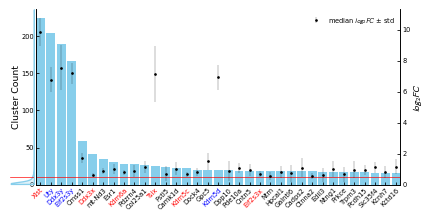

In [11]:
import seaborn as sns

from matplotlib import pyplot as plt

head_data = gene_sig_data.drop('C130073E24Rik').head(35)
chromosome_map = pd.read_csv('../../../resources/chromosome_info.csv', index_col='Gene name')['Chromosome/scaffold name'].to_dict()

plt.close('all')
with plt.style.context(RCPARAMS):
    plt.rcParams['axes.spines.right'] = True

    fig = plt.figure(figsize=(110*MM, 58*MM))
    gs = fig.add_gridspec(1, 2, width_ratios=[2, 30], wspace=0.01)

    ax1 = fig.add_subplot(gs[0, 1])
    ax2 = ax1.twinx()
    ax3 = fig.add_subplot(gs[0, 0])
    # ax4 = fig.add_subplot(gs[0, 2])


    # Main Barplot --------------------------------------------------------------- #

    x_labels = head_data.index  # or whatever your gene labels are
    y_values = head_data['No. of Cluster with DGE']

    bar_width = 0.85

    x_pos = np.arange(len(x_labels))
    ax1.bar(x_pos, y_values, color='skyblue', width=bar_width)
    ax1.grid(False)
    ax1.spines['top'].set_visible(False)

    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(
        x_labels,
        rotation=45,
        ha='right',            # right-align labels
        rotation_mode='anchor', # ensures rotation respects alignment
    )
    ax1.set_xlim(-bar_width/2, len(x_labels) - 1 + bar_width/2)

    ax1.axhline(y=10, c='r', linestyle='-', linewidth=0.5)

    chromosomes = [chromosome_map.get(gene, 'UNMAPPED') for gene in head_data.index]
    for tick, chrom in zip(ax1.get_xticklabels(), chromosomes):
        if chrom == 'X':
            tick.set_color('red')
        elif chrom == 'Y':
            tick.set_color('blue')
        else:
            tick.set_color('black')

    ax1.set_ylabel('Cluster Count')


    # LogFC Errorbars ------------------------------------------------------------ #

    ax2.errorbar(
        x=np.arange(len(head_data)),
        y=head_data['logFC'],
        yerr=head_data['logFC_err'],
        fmt='o',
        markersize=1,
        color='#000000',
        label='median $log_{2}FC$ ± std',
        elinewidth=.2,
    )
    ax2.set_ylim(0, None)
    ax2.spines['top'].set_visible(False)

    ax2.set_ylabel(None)
    ax2.legend(loc='upper right', fontsize=5)

    ax2.set_ylabel('$log_{2}FC$', va='top')

    # Side Histogram ------------------------------------------------------------- #

    ax3.set_axisbelow(True)
    sns.kdeplot(
        y=gene_sig_data['No. of Cluster with DGE'], 
        ax=ax3,
        fill=True,
        color='skyblue',
        cut=0
        )
    ax3.invert_xaxis()  # optional, looks more like jointplot style
    ax3.set_ylim(0, 225)
    ax3.axis('off')

    ax3.axhline(y=10, c='r', linestyle='-', linewidth=0.5)
    
    fig.subplots_adjust(bottom=0.2, left=0, right=.94, top=1)
    # fig.savefig('results/figures/common-barchart.pdf', transparent=True)
    fig.savefig(FIGUREDIR / 'subplot_a_global_barchat.pdf', transparent=True)
    plt.show();